In [30]:
# Final term project - Part 1 (EDA) and Part 2 (Probability distributions)
# Dataset: insurance.csv (medical insurance charges)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import os

In [31]:
FILE_PATH = "../shared/insurance.csv"
# folder where the charts will be saved
CHART_FOLDER = "charts"


# make the chart folder if it is not there yet
os.makedirs(CHART_FOLDER, exist_ok=True)

#  1. Khám phá dữ liệu (Exploratory Data Analysis - EDA)

### 1.1 Tóm tắt thông tin dữ liệu:


#### Kiểm tra số lượng bản ghi, số lượng biến số, kiểu dữ liệu của từng biến.

In [32]:
# ----------  look at the data ----------
print("===== DATA SUMMARY =====")
df = pd.read_csv(FILE_PATH)

# first 5 rows just to see what it looks like
print(df.head())

# how many rows and columns
print("\nNumber of rows and columns:", df.shape)

# type of each column
print("\nData types:")
print(df.dtypes)

# split the columns by type, so we do not need to type the names by hand
number_cols = df.select_dtypes(include="number").columns.tolist()
text_cols = df.select_dtypes(exclude="number").columns.tolist()
print("\nNumber columns:", number_cols)
print("Text columns:", text_cols)

===== DATA SUMMARY =====
   age     sex     bmi  children smoker     region      charges
0   19  female  27.900         0    yes  southwest  16884.92400
1   18    male  33.770         1     no  southeast   1725.55230
2   28    male  33.000         3     no  southeast   4449.46200
3   33    male  22.705         0     no  northwest  21984.47061
4   32    male  28.880         0     no  northwest   3866.85520

Number of rows and columns: (1338, 7)

Data types:
age           int64
sex             str
bmi         float64
children      int64
smoker          str
region          str
charges     float64
dtype: object

Number columns: ['age', 'bmi', 'children', 'charges']
Text columns: ['sex', 'smoker', 'region']


#### Xử lý dữ liệu thiếu, dữ liệu trùng lặp

In [33]:
# ----------  missing and duplicated data ----------
print("\n===== MISSING AND DUPLICATE =====")

# count missing values in each column
missing = df.isnull().sum()
print("Missing values per column:")
print(missing)

# if there is missing data, drop those rows
n_missing = missing.sum()
if n_missing > 0:
    df = df.dropna()
    print("Dropped the rows with missing values, rows left:", len(df))
else:
    print("No missing values, nothing to fix")

# count duplicated rows
n_duplicates = df.duplicated().sum()
print("\nNumber of duplicated rows:", n_duplicates)

# if there are duplicates, show them and keep only the first one
if n_duplicates > 0:
    print(df[df.duplicated(keep=False)])
    df = df.drop_duplicates()
    print("Rows after removing duplicates:", len(df))

# Then output that cleaned dataset to shared, or local.
if os.path.exists("../shared/"):
    df.to_csv("../shared/insurance_cleaned.csv", index=False)
    print("Cleaned data saved to ../shared/insurance/insurance_cleaned.csv")
else:
    df.to_csv("insurance_cleaned.csv", index=False)
    print("Cleaned data saved to current folder(insurance_cleaned)")


===== MISSING AND DUPLICATE =====
Missing values per column:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64
No missing values, nothing to fix

Number of duplicated rows: 1
     age   sex    bmi  children smoker     region    charges
195   19  male  30.59         0     no  northwest  1639.5631
581   19  male  30.59         0     no  northwest  1639.5631
Rows after removing duplicates: 1337
Cleaned data saved to ../shared/insurance/insurance_cleaned.csv


### 1.2 Phân tích thống kê mô tả:

#### Tính các thống kê như trung bình, trung vị, độ lệch chuẩn, tứ phân vị.

In [34]:
# ----------  descriptive statistics ----------
print("\n=====  DESCRIPTIVE STATISTICS =====")

# mean, median, std, and quartiles (25%, 50%, 75%) for each number column
for col in number_cols:
    print("\n--- " + col + " ---")
    print("Mean:", round(df[col].mean(), 2))
    print("Median:", round(df[col].median(), 2))
    print("Std:", round(df[col].std(), 2))
    print("Min:", df[col].min())
    print("Q1 (25%):", round(df[col].quantile(0.25), 2))
    print("Q3 (75%):", round(df[col].quantile(0.75), 2))
    print("Max:", df[col].max())
    # skewness tells us if the data leans to one side (0 = balanced)
    print("Skewness:", round(df[col].skew(), 2)) # type:ignore

# Pick the numeric column with the highest standard deviation (largest spread) as our main target to compare groups
TARGET = df[number_cols].std().idxmax()
print("\nMain target column (largest spread):", TARGET)

# the text columns, count how many of each group
for col in text_cols:
    print("\n--- " + col + " ---")
    print(df[col].value_counts())

# the main number column for each group of every text column
for col in text_cols:
    print("\n" + TARGET + " by " + col + ":")
    print(df.groupby(col)[TARGET].agg(["mean", "median", "std", "count"]).round(2))


=====  DESCRIPTIVE STATISTICS =====

--- age ---
Mean: 39.22
Median: 39.0
Std: 14.04
Min: 18
Q1 (25%): 27.0
Q3 (75%): 51.0
Max: 64
Skewness: 0.05

--- bmi ---
Mean: 30.66
Median: 30.4
Std: 6.1
Min: 15.96
Q1 (25%): 26.29
Q3 (75%): 34.7
Max: 53.13
Skewness: 0.28

--- children ---
Mean: 1.1
Median: 1.0
Std: 1.21
Min: 0
Q1 (25%): 0.0
Q3 (75%): 2.0
Max: 5
Skewness: 0.94

--- charges ---
Mean: 13279.12
Median: 9386.16
Std: 12110.36
Min: 1121.8739
Q1 (25%): 4746.34
Q3 (75%): 16657.72
Max: 63770.42801
Skewness: 1.52

Main target column (largest spread): charges

--- sex ---
sex
male      675
female    662
Name: count, dtype: int64

--- smoker ---
smoker
no     1063
yes     274
Name: count, dtype: int64

--- region ---
region
southeast    364
southwest    325
northwest    324
northeast    324
Name: count, dtype: int64

charges by sex:
            mean   median       std  count
sex                                       
female  12569.58  9412.96  11128.70    662
male    13975.00  9377.90  12971

#### Trực quan hoá bằng các biểu đồ phù hợp


=====  CHARTS =====


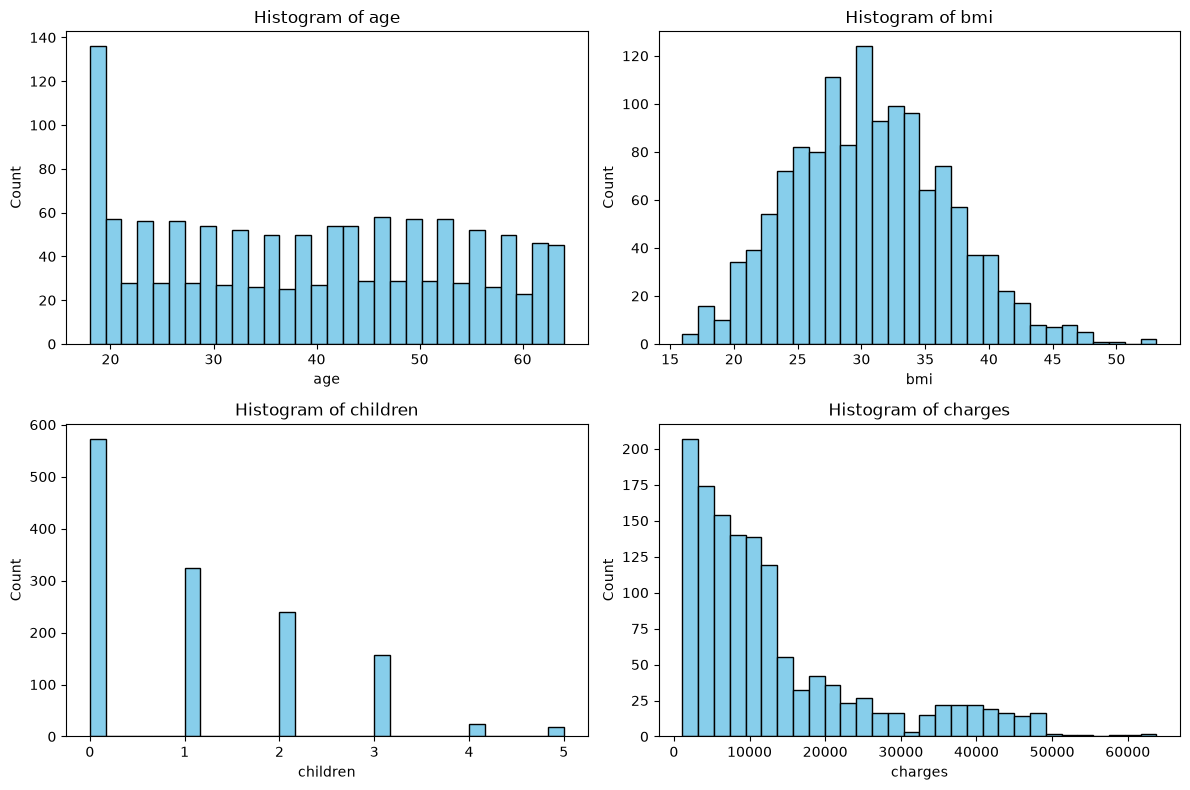

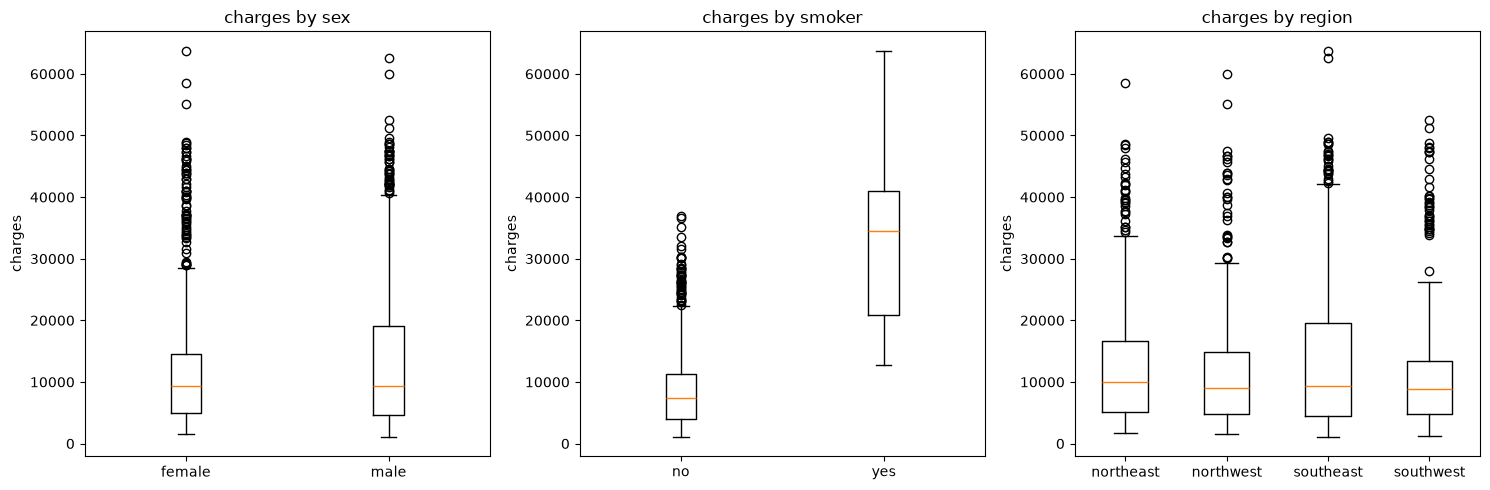

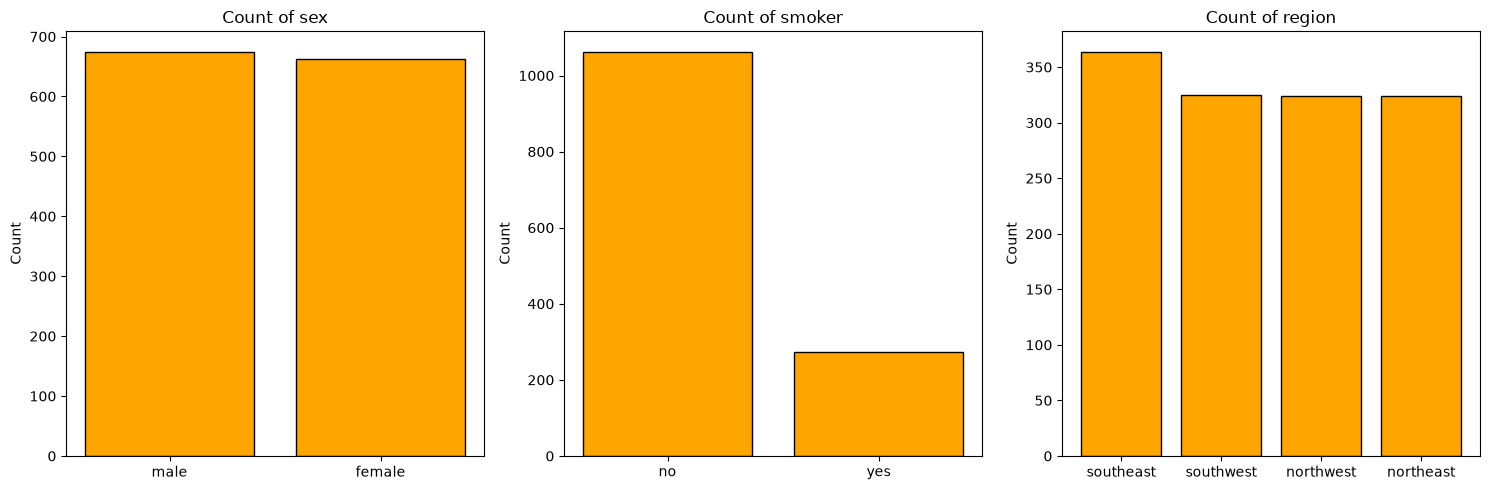

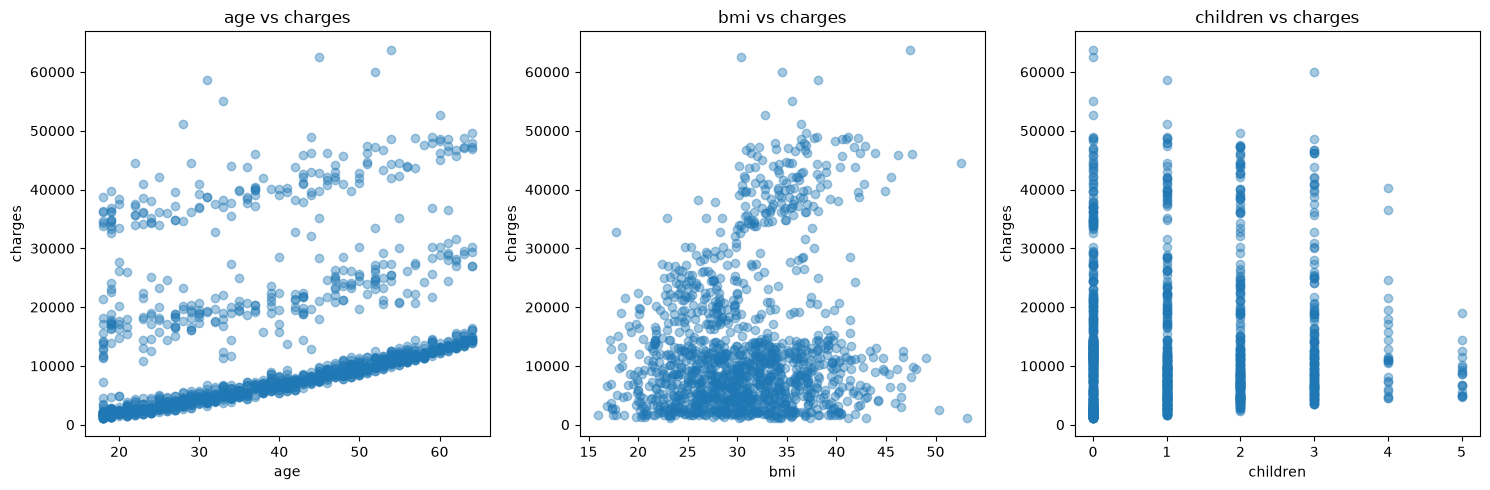

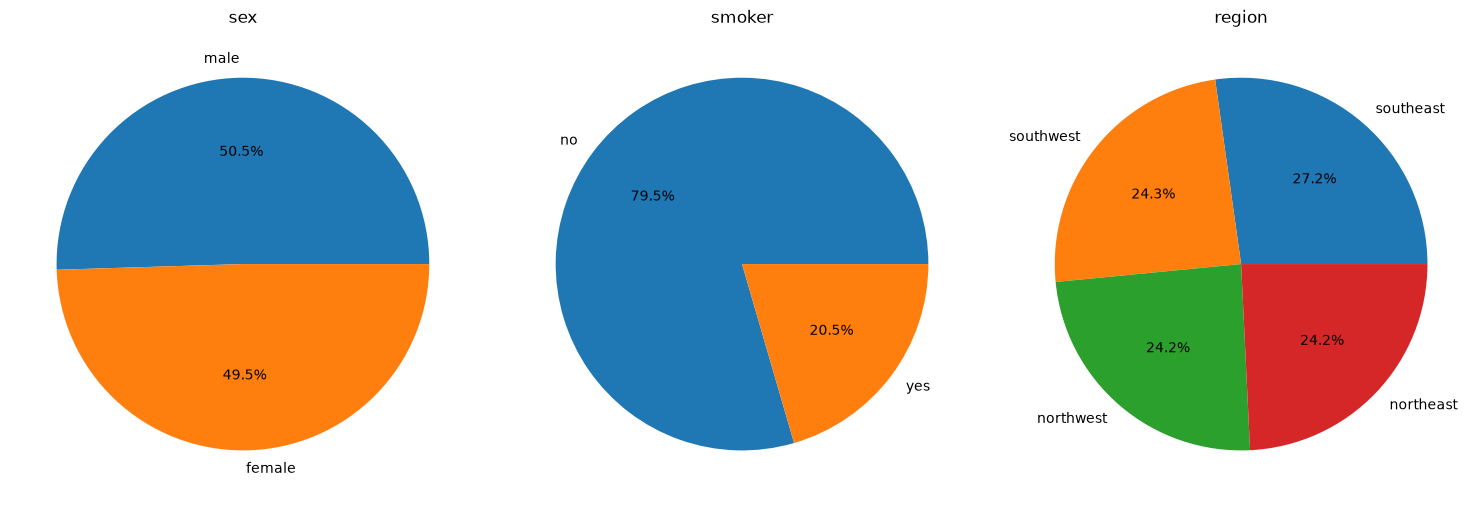

In [35]:
# ----------  charts ----------
print("\n=====  CHARTS =====")

# Chart 1: histograms of every number column
# why: histogram shows the shape of a number column (balanced or skewed)
rows = int(np.ceil(len(number_cols) / 2))
plt.figure(figsize=(12, 4 * rows))
for i, col in enumerate(number_cols):
    plt.subplot(rows, 2, i + 1)
    plt.hist(df[col], bins=30, color="skyblue", edgecolor="black")
    plt.title("Histogram of " + col)
    plt.xlabel(col)
    plt.ylabel("Count")
plt.tight_layout()
plt.savefig(CHART_FOLDER + "/1_histograms.png")
plt.show()

# Chart 2: boxplot of TARGET for the groups of every text column
# why: boxplot is good for comparing groups and it shows the outliers as dots
plt.figure(figsize=(5 * len(text_cols), 5))
for i, cat in enumerate(text_cols):
    groups = sorted(df[cat].unique())
    data = [df[df[cat] == g][TARGET] for g in groups]
    plt.subplot(1, len(text_cols), i + 1)
    plt.boxplot(data)
    plt.xticks(range(1, len(groups) + 1), groups)
    plt.title(TARGET + " by " + cat)
    plt.ylabel(TARGET)
plt.tight_layout()
plt.savefig(CHART_FOLDER + "/2_boxplot_groups.png")
plt.show()

# Chart 3: bar chart of the number of people in each group of every text column
# why: bar chart is the normal way to show counts of a text column
plt.figure(figsize=(5 * len(text_cols), 5))
for i, cat in enumerate(text_cols):
    counts = df[cat].value_counts()
    plt.subplot(1, len(text_cols), i + 1)
    plt.bar(counts.index, counts.values, color="orange", edgecolor="black") # type:ignore
    plt.title("Count of " + cat)
    plt.ylabel("Count")
plt.tight_layout()
plt.savefig(CHART_FOLDER + "/3_bar_counts.png")
plt.show()

# Chart 4: scatter plot of TARGET vs every other number column
# why: scatter plot shows if two number columns are related
other_cols = [c for c in number_cols if c != TARGET]
plt.figure(figsize=(5 * len(other_cols), 5))
for i, col in enumerate(other_cols):
    plt.subplot(1, len(other_cols), i + 1)
    plt.scatter(df[col], df[TARGET], alpha=0.4)
    plt.title(col + " vs " + TARGET)
    plt.xlabel(col)
    plt.ylabel(TARGET)
plt.tight_layout()
plt.savefig(CHART_FOLDER + "/4_scatter_target.png")
plt.show()

# Chart 5: pie chart of every text column
# why: pie chart shows the percentage of each group
plt.figure(figsize=(5 * len(text_cols), 5))
for i, cat in enumerate(text_cols):
    counts = df[cat].value_counts()
    plt.subplot(1, len(text_cols), i + 1)
    plt.pie(counts.values, labels=counts.index, autopct="%1.1f%%") #type:ignore
    plt.title(cat)
plt.tight_layout()
plt.savefig(CHART_FOLDER + "/5_pie_groups.png")
plt.show()

### 1.3 Phát hiện dữ liệu ngoại lai:

#### Trình bày các phương pháp để xác định giá trị ngoại lai và đề xuất phương pháp xử lý.


=====  OUTLIERS =====

--- age ---
Lower limit: -9.0  Upper limit: 87.0
Outliers by IQR: 0
   below lower limit: 0
   above upper limit: 0
Outliers by z-score: 0
   z < -3 (too low): 0
   z > 3 (too high): 0
Conclusion: no outliers, nothing to do

--- bmi ---
Lower limit: 13.67  Upper limit: 47.32
Outliers by IQR: 9
   below lower limit: 0
   above upper limit: 9
Outliers by z-score: 4
   z < -3 (too low): 0
   z > 3 (too high): 4
   lowest outlier value: 47.41
   highest outlier value: 53.13

   Who are the outliers of bmi? (% of outliers vs % of everyone)
        outliers %  everyone %  difference
sex                                       
male          66.7        50.5        16.2
female        33.3        49.5       -16.2
        outliers %  everyone %  difference
smoker                                    
no            66.7        79.5       -12.8
yes           33.3        20.5        12.8
           outliers %  everyone %  difference
region                                       

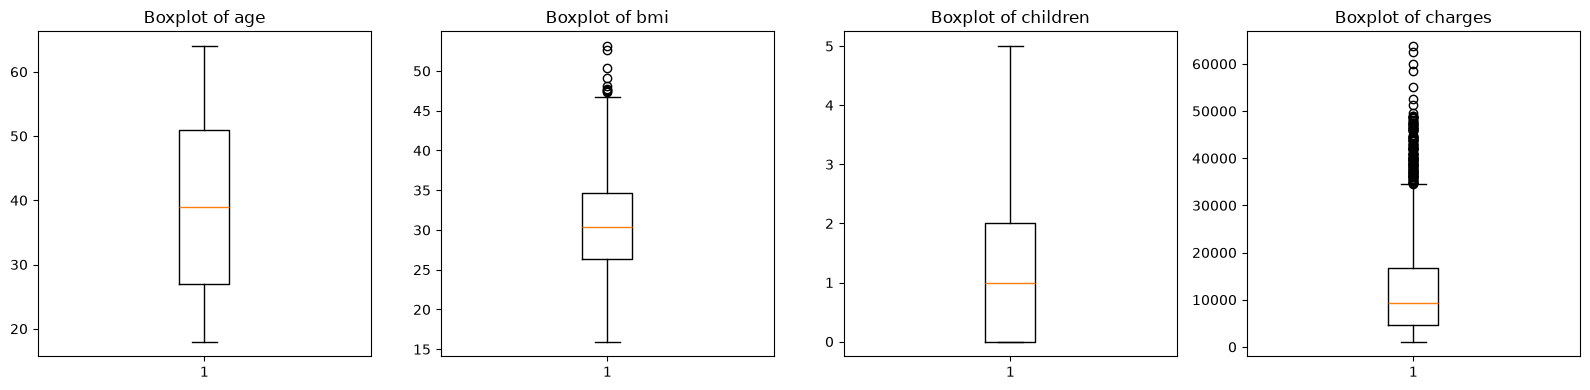

In [36]:
# ----------  outliers ----------
print("\n=====  OUTLIERS =====")

# Method 1: IQR rule
# a value is an outlier if it is lower than Q1 - 1.5*IQR or higher than Q3 + 1.5*IQR
# Method 2: z-score
# a value is an outlier if it is more than 3 std away from the mean
# text columns can not have outliers, we only test number columns

summary = []   # we save the results here for the table at the end

for col in number_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    # split the IQR outliers into below the lower limit and above the upper limit
    below_lower = df[df[col] < lower]
    above_upper = df[df[col] > upper]
    iqr_total = len(below_lower) + len(above_upper)

    # same for z-score: far below the mean (z < -3) or far above the mean (z > 3)
    z = (df[col] - df[col].mean()) / df[col].std()
    z_below = df[z < -3]
    z_above = df[z > 3]
    z_total = len(z_below) + len(z_above)

    print("\n--- " + col + " ---")
    print("Lower limit:", round(lower, 2), " Upper limit:", round(upper, 2))
    print("Outliers by IQR:", iqr_total)
    print("   below lower limit:", len(below_lower))
    print("   above upper limit:", len(above_upper))
    print("Outliers by z-score:", z_total)
    print("   z < -3 (too low):", len(z_below))
    print("   z > 3 (too high):", len(z_above))

    # all outlier rows from both methods together (no double counting)
    all_outliers = df[(df[col] < lower) | (df[col] > upper) | (z < -3) | (z > 3)]

    if len(all_outliers) > 0:
        # show the lowest / highest outlier value
        print("   lowest outlier value:", all_outliers[col].min())
        print("   highest outlier value:", all_outliers[col].max())

        # who are the outliers? compare the % of each group in the outliers vs in everyone
        print("\n   Who are the outliers of " + col + "? (% of outliers vs % of everyone)")
        for cat in text_cols:
            outlier_pct = all_outliers[cat].value_counts(normalize=True) * 100
            overall_pct = df[cat].value_counts(normalize=True) * 100
            table = pd.DataFrame({"outliers %": outlier_pct, "everyone %": overall_pct}).fillna(0).round(1)
            table["difference"] = (table["outliers %"] - table["everyone %"]).round(1)
            print(table)
            # if one group is 20 points or more different, point it out
            biggest = table["difference"].idxmax()
            if abs(table.loc[biggest, "difference"]) >= 20: # type:ignore
                print("   -> outliers are very different in", cat, "(group:", biggest, ")")

    # conclusion for this column (the code decides by itself)
    percent = round(iqr_total / len(df) * 100, 1)
    if iqr_total == 0 and z_total == 0:
        decision = "no outliers, nothing to do"
    elif percent > 5:
        decision = "many outliers, they are part of the normal spread (skewed data) -> keep them"
    else:
        decision = "few outliers -> look at the values above, keep them if they are realistic"
    print("Conclusion:", decision)

    summary.append([col, iqr_total, len(below_lower), len(above_upper), percent, z_total, decision])

# summary table of all columns
print("\n----- SUMMARY OF ALL COLUMNS -----")
summary_table = pd.DataFrame(summary, columns=["column", "IQR outliers", "below lower", "above upper", "IQR %", "z-score outliers", "decision"])
print(summary_table.to_string(index=False))

# boxplots of every number column to see the outliers
plt.figure(figsize=(4 * len(number_cols), 4))
for i, col in enumerate(number_cols):
    plt.subplot(1, len(number_cols), i + 1)
    plt.boxplot(df[col])
    plt.title("Boxplot of " + col)
plt.tight_layout()
plt.savefig(CHART_FOLDER + "/6_boxplot_outliers.png")
plt.show()

# If a column has many outliers we can take log() of it later
# so the extreme values do not push the results too much, instead of deleting them

### 1.4 Nhận xét tổng quan về tập dữ liệu:

#### Đưa ra các đặc điểm nổi bật của dữ liệu dựa trên các phân tích trên.

In [37]:
# ---------- overall remarks ----------
# everything here is calculated from the data, nothing is typed by hand
print("\n=====  OVERALL REMARKS =====")
print("Rows:", len(df), " Columns:", df.shape[1])
print("Missing values found:", n_missing, " Duplicate rows removed:", n_duplicates)

# shape of each number column (rule of thumb for skewness: under 0.5 balanced, over 1 strongly skewed)
print("\nShape of each number column:")
for col in number_cols:
    skew = df[col].skew()
    if abs(skew) < 0.5: #type: ignore
        shape = "fairly balanced"
    elif abs(skew) < 1: #type: ignore
        shape = "a bit skewed"
    else:
        shape = "strongly skewed"
    if skew > 0: #type: ignore
        side = "(long tail on the right)"
    else:
        side = "(long tail on the left)"
    if abs(skew) < 0.5: #type: ignore
        side = ""
    print(col + ": mean", round(df[col].mean(), 2), "median", round(df[col].median(), 2), "->", shape, side)

# outliers from the table above
print("\nColumns with outliers:")
for i in range(len(summary_table)):
    row = summary_table.iloc[i]
    if row["IQR outliers"] > 0 or row["z-score outliers"] > 0:
        print(row["column"] + ": IQR =", row["IQR outliers"], " z-score =", row["z-score outliers"])

# which text column makes the biggest difference in TARGET?
print("\nGroup differences in " + TARGET + ":")
best_cat = ""
best_ratio = 0
for cat in text_cols:
    means = df.groupby(cat)[TARGET].mean()
    ratio = means.max() / means.min()
    print(cat + ": highest group =", means.idxmax(), round(means.max(), 1),
          "| lowest group =", means.idxmin(), round(means.min(), 1),
          "| highest is", round(ratio, 2), "times the lowest")
    if ratio > best_ratio:
        best_ratio = ratio
        best_cat = cat
print("-> the biggest difference in " + TARGET + " is between the groups of:", best_cat)


=====  OVERALL REMARKS =====
Rows: 1337  Columns: 7
Missing values found: 0  Duplicate rows removed: 1

Shape of each number column:
age: mean 39.22 median 39.0 -> fairly balanced 
bmi: mean 30.66 median 30.4 -> fairly balanced 
children: mean 1.1 median 1.0 -> a bit skewed (long tail on the right)
charges: mean 13279.12 median 9386.16 -> strongly skewed (long tail on the right)

Columns with outliers:
bmi: IQR = 9  z-score = 4
children: IQR = 0  z-score = 18
charges: IQR = 139  z-score = 7

Group differences in charges:
sex: highest group = male 13975.0 | lowest group = female 12569.6 | highest is 1.11 times the lowest
smoker: highest group = yes 32050.2 | lowest group = no 8440.7 | highest is 3.8 times the lowest
region: highest group = southeast 14735.4 | lowest group = southwest 12346.9 | highest is 1.19 times the lowest
-> the biggest difference in charges is between the groups of: smoker


#  2. Phân tích phân phối xác suất

## 2.1 Chọn ít nhất hai biến số quan trọng và kiểm tra xem nó có tuân theo phân phối xác suất nào không

In [38]:
# ---------- 2.1 which columns to test ----------
# number columns with whole numbers and only a few different values are "counts"
# (like number of children), we check them with Poisson
# the other number columns are "continuous", we check them with normal, uniform, etc.
count_cols = [c for c in number_cols if str(df[c].dtype).startswith("int") and df[c].nunique() <= 10]
continuous_cols = [c for c in number_cols if c not in count_cols]
print("Continuous columns:", continuous_cols)
print("Count columns:", count_cols)

Continuous columns: ['age', 'bmi', 'charges']
Count columns: ['children']


KS critical threshold for good fit: 0.0372

--- age ---
Shapiro p-value: 6.21045161424606e-22
p < 0.05 -> strictly not normal
KS statistic (smaller is better):
   normal: 0.079
   uniform: 0.08
   exponential: 0.144
   lognormal: 0.1
Closest curve of the ones tested: normal | KS = 0.079 -> no curve fits well


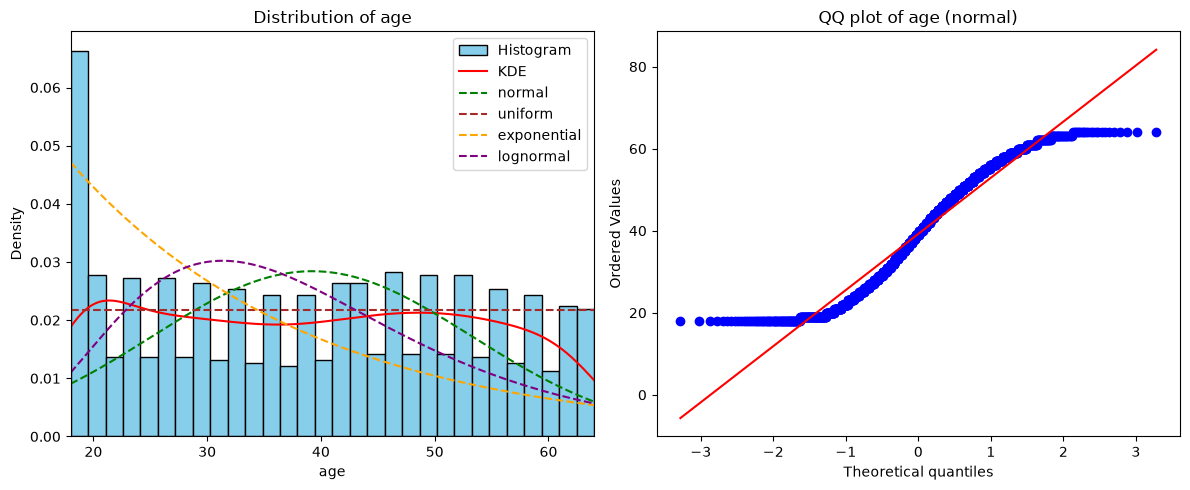


--- bmi ---
Shapiro p-value: 2.5752925663919847e-05
p < 0.05 -> strictly not normal
KS statistic (smaller is better):
   normal: 0.026
   uniform: 0.295
   exponential: 0.283
   lognormal: 0.032
Closest curve of the ones tested: normal | KS = 0.026 -> good fit


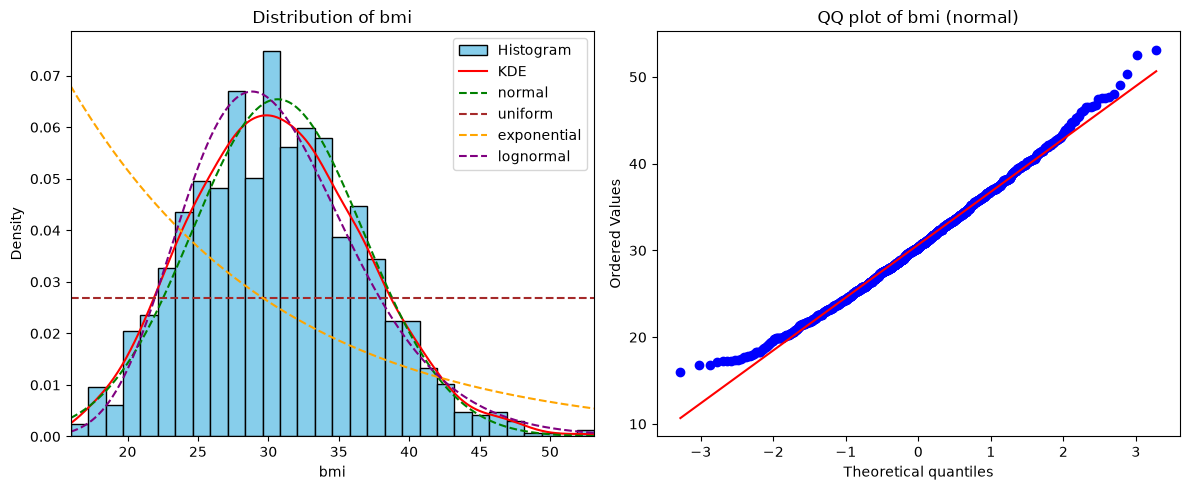


--- charges ---
Shapiro p-value: 1.1959741617200278e-36
p < 0.05 -> strictly not normal
KS statistic (smaller is better):
   normal: 0.189
   uniform: 0.515
   exponential: 0.061
   lognormal: 0.037
Closest curve of the ones tested: lognormal | KS = 0.037 -> good fit


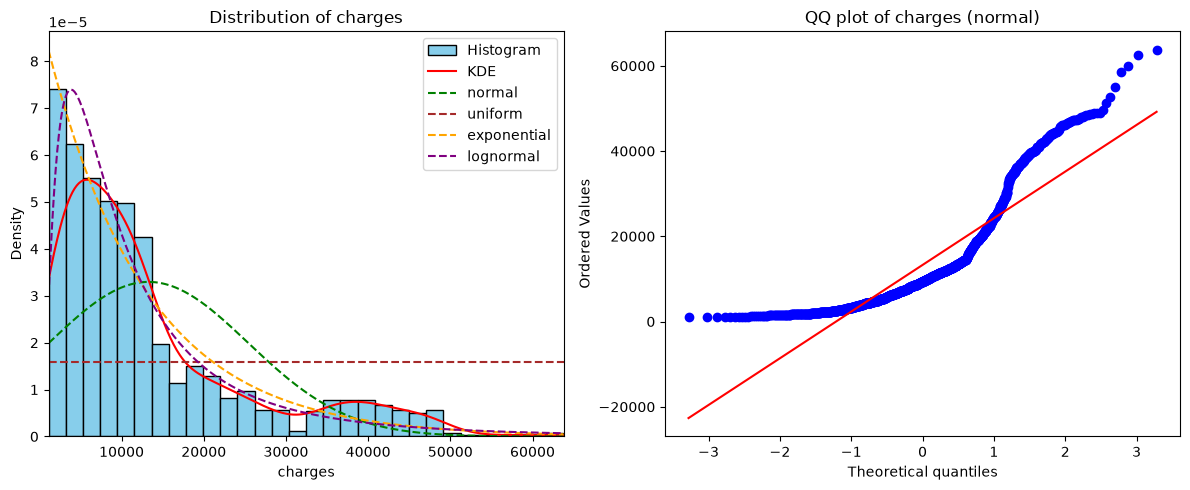

Skewness of charges: 1.52
Skewness of log(charges): -0.09
Shapiro p-value of log(charges): 2.573187234529489e-11 -> still not normal (multiple subgroups)


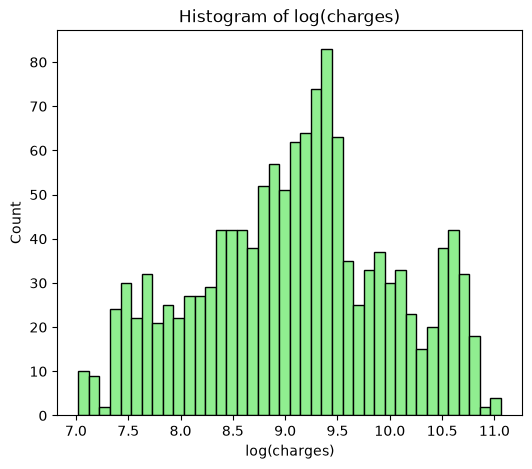

In [39]:
# ---------- 2.2 continuous columns ----------
# for every continuous column:
# 1) Shapiro-Wilk test for normal. H0: data is normal. p-value < 0.05 = reject H0 (not normal)
# 2) try to fit some curves and compare them with the KS statistic
#    (smaller KS number = the curve fits the data better)
#    note: I only use the KS number to compare, not its p-value, because the curve
#    was made from the same data so the p-value is too optimistic
results = []   # save the results for the conclusion at the end

GOOD_FIT = 1.36 / np.sqrt(len(df))  # KS critical value at alpha = 0.05 (~0.037)
print("KS critical threshold for good fit:", round(GOOD_FIT, 4))
for col in continuous_cols:
    data = df[col]
    print("\n--- " + col + " ---")

    # Shapiro test
    shapiro_p = stats.shapiro(data)[1]
    print("Shapiro p-value:", shapiro_p)
    if shapiro_p < 0.05:
        print("p < 0.05 -> strictly not normal")
    else:
        print("p >= 0.05 -> looks normal")

    # fit the curves
    fits = {}
    fits["normal"] = (stats.norm, stats.norm.fit(data))
    fits["uniform"] = (stats.uniform, stats.uniform.fit(data)) #type:ignore
    fits["exponential"] = (stats.expon, stats.expon.fit(data)) #type:ignore
    # lognormal only works if all values are bigger than 0
    if data.min() > 0:
        fits["lognormal"] = (stats.lognorm, stats.lognorm.fit(data, floc=0)) #type:ignore

    # KS statistic of each curve
    ks_values = {}
    for name in fits:
        dist, params = fits[name]
        ks_values[name] = stats.kstest(data, dist.cdf, args=params).statistic
    print("KS statistic (smaller is better):")
    for name in ks_values:
        print("  ", name + ":", round(ks_values[name], 3))

    # the best curve is the one with the smallest KS number
    best = min(ks_values, key=ks_values.get) #type:ignore
    if ks_values[best] < GOOD_FIT:
        verdict = "good fit"
    else:
        verdict = "no curve fits well"
    print("Closest curve of the ones tested:", best, "| KS =", round(ks_values[best], 3), "->", verdict)
    results.append([col, shapiro_p, best, ks_values[best], verdict, data.skew()])

    # charts: histogram + KDE + the curves, and a QQ plot
    colors = {"normal": "green", "uniform": "brown", "exponential": "orange", "lognormal": "purple"}
    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    plt.hist(data, bins=30, density=True, color="skyblue", edgecolor="black", label="Histogram")
    data.plot(kind="kde", color="red", label="KDE")
    x = np.linspace(data.min(), data.max(), 300)
    for name in fits:
        dist, params = fits[name]
        plt.plot(x, dist.pdf(x, *params), color=colors[name], linestyle="--", label=name)
    plt.title("Distribution of " + col)
    plt.xlabel(col)
    plt.xlim(data.min(), data.max())
    plt.legend()

    # QQ plot: if the dots are on the line then the data is normal
    plt.subplot(1, 2, 2)
    stats.probplot(data, dist="norm", plot=plt)
    plt.title("QQ plot of " + col + " (normal)")

    plt.tight_layout()
    plt.savefig(CHART_FOLDER + "/7_distribution_" + col + ".png")
    plt.show()

    # if the column is strongly skewed to the right, see what log() does
    if data.skew() > 1 and data.min() > 0: #type:ignore
        log_data = np.log(data)
        print("Skewness of", col + ":", round(data.skew(), 2)) #type:ignore 
        print("Skewness of log(" + col + "):", round(log_data.skew(), 2)) #type:ignore
        log_shapiro_p = stats.shapiro(log_data)[1]
        print("Shapiro p-value of log(" + col + "):", log_shapiro_p,"-> still not normal (multiple subgroups)" if log_shapiro_p < 0.05 else "-> normal now")
        plt.figure(figsize=(6, 5))
        plt.hist(log_data, bins=40, color="lightgreen", edgecolor="black")
        plt.title("Histogram of log(" + col + ")")
        plt.xlabel("log(" + col + ")")
        plt.ylabel("Count")
        plt.savefig(CHART_FOLDER + "/8_log_" + col + ".png")
        plt.show()


--- children ---
Mean: 1.1  Variance: 1.45  Variance / Mean: 1.33

children | Observed | Expected if Poisson
0 | 573 | 447
1 | 324 | 490
2 | 240 | 268
3 | 157 | 98
4 | 25 | 27
5 | 18 | 7
Chi-square test p-value: 1.022503816787475e-30
Conclusion: p < 0.05 (Var/Mean = 1.33) -> reject Poisson (not Poisson)


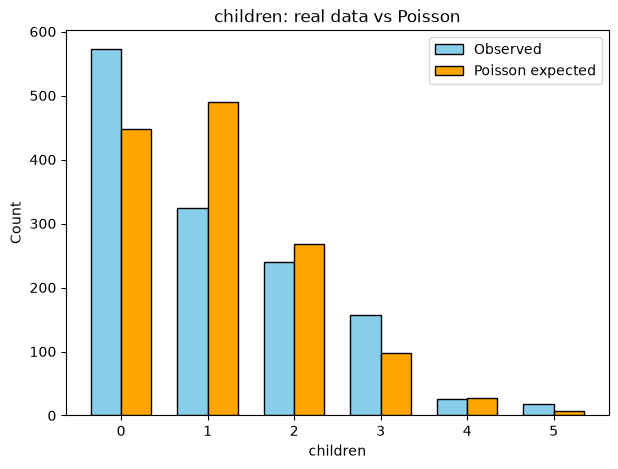

In [40]:
# ---------- 2.3 count columns (Poisson?) ----------
poisson_results = []

for col in count_cols:
    data = df[col]
    c_mean = data.mean()
    c_var = data.var()
    ratio = c_var / c_mean
    print("\n--- " + col + " ---")
    print("Mean:", round(c_mean, 2), " Variance:", round(c_var, 2), " Variance / Mean:", round(ratio, 2))
    # for Poisson the mean and the variance should be about the same (ratio near 1)

    # observed = how many people have 0,1,2,... (real data)
    observed = data.value_counts().sort_index()
    # expected = how many we should see if it was Poisson
    # the last group is "this number or more", so we use 1 - cdf for it
    expected = stats.poisson.pmf(observed.index, c_mean) * len(data)
    expected[-1] = (1 - stats.poisson.cdf(observed.index[-1] - 1, c_mean)) * len(data) #type:ignore

    print("\n" + col + " | Observed | Expected if Poisson")
    for k, o, e in zip(observed.index, observed.values, expected): #type:ignore
        print(k, "|", o, "|", round(e))

    # rule of thumb: ratio between 0.8 and 1.2 = close to Poisson
    if ratio > 1.2:
        chi2_stat, pois_p = stats.chisquare(observed.values, f_exp=expected, ddof=1)
        print("Chi-square test p-value:", pois_p)
    if pois_p < 0.05: 
      verdict = f"p < 0.05 (Var/Mean = {round(ratio, 2)}) -> reject Poisson (not Poisson)"
    else:
      verdict = "p >= 0.05 -> fits Poisson"
    print("Conclusion:", verdict)
    poisson_results.append([col, c_mean, c_var, verdict])

    # bar chart observed vs expected
    plt.figure(figsize=(7, 5))
    width = 0.35
    plt.bar(observed.index - width / 2, observed.values, width, label="Observed", color="skyblue", edgecolor="black") #type:ignore
    plt.bar(observed.index + width / 2, expected, width, label="Poisson expected", color="orange", edgecolor="black") 
    plt.title(col + ": real data vs Poisson")
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.legend()
    plt.savefig(CHART_FOLDER + "/9_poisson_" + col + ".png")
    plt.show()

## 2.2 Đưa ra nhận xét về đặc điểm của dữ liệu dựa trên phân phối.

In [41]:
# ---------- conclusion for part 2 ----------
# everything here comes from the results above
print("\n===== CONCLUSION =====")
for r in results:
    print(r[0] + ": best curve is", r[2], "(KS =", round(r[3], 3), ") ->", r[4], #type:ignore
          "| Shapiro p =", "{:.2e}".format(r[1]), "| skewness =", round(r[5], 2)) #type:ignore
for r in poisson_results:
    print(r[0] + ": mean", round(r[1], 2), "variance", round(r[2], 2), "->", r[3]) #type:ignore

print("\nDone! Charts are saved in the folder:", CHART_FOLDER)


===== CONCLUSION =====
age: best curve is normal (KS = 0.079 ) -> no curve fits well | Shapiro p = 6.21e-22 | skewness = 0.05
bmi: best curve is normal (KS = 0.026 ) -> good fit | Shapiro p = 2.58e-05 | skewness = 0.28
charges: best curve is lognormal (KS = 0.037 ) -> good fit | Shapiro p = 1.20e-36 | skewness = 1.52
children: mean 1.1 variance 1.45 -> p < 0.05 (Var/Mean = 1.33) -> reject Poisson (not Poisson)

Done! Charts are saved in the folder: charts
